# Smart Outcome Predictor

# Part A: Conceptual Foundation (Theory)

**1. What are Ensemble Learning Methods and why are they effective?**
Ensemble learning combines predictions of **multiple models** (base learners) to build one stronger model.
They work because different models make *different errors*; when we average / vote / chain them, the errors cancel out.
Result: higher accuracy, better generalization and more stable predictions than a single model.

**2. Difference between Bagging, Boosting and Voting**
- **Bagging:** many models trained **in parallel** on random bootstrap samples; predictions are averaged/voted → **reduces variance** (e.g., Random Forest).
- **Boosting:** models trained **sequentially**; each new model focuses on the mistakes of the previous one → **reduces bias** (e.g., AdaBoost, XGBoost).
- **Voting:** *different types* of models (LR, KNN, Tree...) are trained on the same data and their predictions are combined by majority vote (hard) or average probability (soft).

**3. Bias–Variance Trade-off and how ensembles address it**
Bias = error from too simple a model (underfitting); Variance = error from too sensitive a model (overfitting).
Reducing one usually increases the other. **Bagging lowers variance** (averaging many deep trees) and **boosting lowers bias** (adding learners that fix residual errors), so ensembles reach a better balance.

**4. Voting Classifier and Stacking Ensemble**
- **Voting Classifier:** combines diverse base classifiers; *hard* = majority class, *soft* = average of predicted probabilities.
- **Stacking:** base models' predictions (out-of-fold) become *input features* for a **meta-learner** (e.g., Logistic Regression) which learns how best to combine them.

**5. AdaBoost vs XGBoost (conceptual)**
- **AdaBoost:** uses weak learners (stumps); increases the **weights of misclassified samples** each round; final output = weighted vote. Simple, but sensitive to noise/outliers.
- **XGBoost:** gradient boosting; each tree fits the **gradient (residual errors)** of the loss; has **L1/L2 regularization, shrinkage, subsampling, handling of missing values, parallel tree building** → usually faster and more accurate and robust.

# Setup Imports & Helper Functions

In [35]:
import os, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor,
                              AdaBoostClassifier, AdaBoostRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor,
                              VotingClassifier, StackingClassifier, StackingRegressor)
from xgboost import XGBClassifier, XGBRegressor

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, root_mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("screenshots", exist_ok=True)
os.makedirs("models", exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"screenshots/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

# Part B: Dataset Understanding & Preparation

In [36]:
df = pd.read_excel("data/Smart_Outcome_Predictor_Dataset_5200.xlsx")
print("Shape:", df.shape)
df.head()

Shape: (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [37]:
df.info()
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   student_id             5200 non-null   int64         
 1   age                    5200 non-null   int64         
 2   country_region         5200 non-null   object        
 3   device_type            5200 non-null   object        
 4   education_background   5200 non-null   object        
 5   course_level           5200 non-null   object        
 6   course_category        5200 non-null   object        
 7   course_start_date      5200 non-null   datetime64[ns]
 8   week_of_year           5200 non-null   int64         
 9   sessions               5200 non-null   int64         
 10  time_spent_hours       5088 non-null   float64       
 11  videos_watched         5200 non-null   int64         
 12  quiz_attempts          5200 non-null   int64         
 13  ass

,count,mean,min,25%,50%,75%,max,std
student_id,5200.0,702600.5,700001.0,701300.75,702600.5,703900.25,705200.0,1501.255031
age,5200.0,24.339615,16.0,20.0,24.0,28.0,45.0,5.578864
course_start_date,5200,2024-07-02 09:45:24.923076864,2024-01-01 00:00:00,2024-04-02 00:00:00,2024-07-02 00:00:00,2024-10-01 00:00:00,2024-12-30 00:00:00,NaN
week_of_year,5200.0,26.621538,1.0,14.0,27.0,40.0,52.0,15.007731
sessions,5200.0,19.121923,1.0,11.0,17.0,25.0,94.0,10.726708
time_spent_hours,5088.0,18.216156,0.6,10.3,16.1,23.8,76.8,10.734114
videos_watched,5200.0,25.852885,0.0,13.0,23.0,35.0,158.0,17.720493
quiz_attempts,5200.0,6.995769,0.0,5.0,7.0,9.0,20.0,2.568017
assignments_submitted,5200.0,3.835769,0.0,2.0,4.0,5.0,12.0,1.951802
forum_posts,5200.0,1.585577,0.0,1.0,1.0,2.0,8.0,1.27064


**Interpretation:** 5200 students, 19 columns. Three numeric columns have missing values (~1.5–2%) → will be imputed. No duplicate rows.

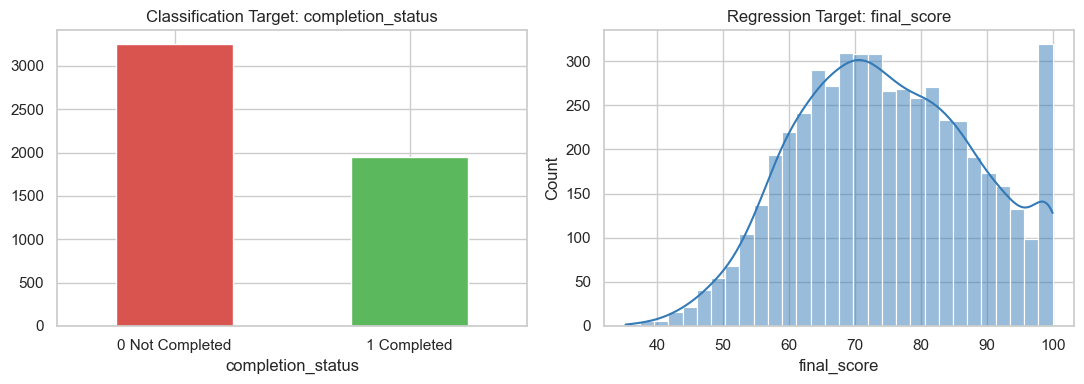

completion_status
0    0.625
1    0.375
Name: proportion, dtype: float64


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["completion_status"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#d9534f", "#5cb85c"])
ax[0].set_title("Classification Target: completion_status"); ax[0].set_xticklabels(["0 Not Completed", "1 Completed"], rotation=0)
sns.histplot(df["final_score"], bins=30, kde=True, ax=ax[1], color="#337ab7")
ax[1].set_title("Regression Target: final_score")
save_fig("01_target_distributions")
print(df["completion_status"].value_counts(normalize=True).round(3))

**Interpretation:** Classes are moderately imbalanced (~63% Not Completed vs ~37% Completed) → we use **stratified split** and look at Precision/Recall/F1, not only Accuracy.

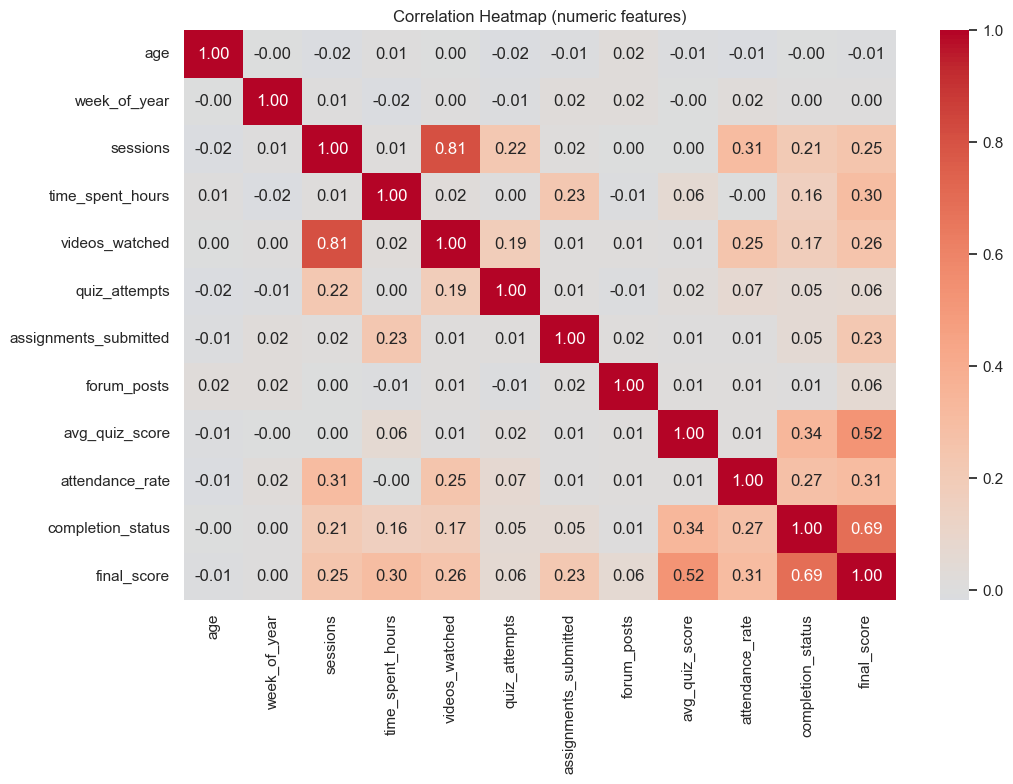

In [39]:
num_df = df.select_dtypes("number").drop(columns=["student_id"])
plt.figure(figsize=(11, 8))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (numeric features)")
save_fig("02_correlation_heatmap")

**Interpretation:** Heatmap shows which engagement/assessment features move together with `completion_status` and `final_score`.

### Task 6 Identify features and target variables

In [40]:
df["start_month"] = pd.to_datetime(df["course_start_date"]).dt.month

TARGET_CLF = "completion_status"
TARGET_REG = "final_score"

NUM_FEATURES = ["age", "week_of_year", "start_month", "sessions", "time_spent_hours", "videos_watched",
                "quiz_attempts", "assignments_submitted", "forum_posts", "avg_quiz_score", "attendance_rate"]
CAT_FEATURES = ["country_region", "device_type", "education_background", "course_level", "course_category"]
FEATURES = NUM_FEATURES + CAT_FEATURES

X = df[FEATURES]
y_clf = df[TARGET_CLF]
y_reg = df[TARGET_REG]

print("Numeric features    :", NUM_FEATURES)
print("Categorical features:", CAT_FEATURES)
print("Dropped             : student_id (ID), course_start_date (-> start_month), other target (leakage)")

Numeric features    : ['age', 'week_of_year', 'start_month', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
Categorical features: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
Dropped             : student_id (ID), course_start_date (-> start_month), other target (leakage)


| Task | Features (X) | Target (y) |
|---|---|---|
| Classification | 11 numeric + 5 categorical | `completion_status` |
| Regression | same 16 features | `final_score` |

### Task 7 Train–test split (80/20) for classification and regression

In [41]:
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_clf, y_reg, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class ratio:", yc_train.mean().round(3), "| Test class ratio:", yc_test.mean().round(3))

Train: (4160, 16) | Test: (1040, 16)
Train class ratio: 0.375 | Test class ratio: 0.375


**Interpretation:** One split (stratified on `completion_status`) is shared by both tasks, so the classification and regression results are on the same students.

### Task 8 Preprocessing (imputation + scaling + encoding)

In [42]:
def make_preprocessor():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num_pipe, NUM_FEATURES),
                              ("cat", cat_pipe, CAT_FEATURES)])

def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

Xt = make_preprocessor().fit_transform(X_train)
print("Shape after preprocessing:", Xt.shape, "(numeric scaled + one-hot encoded)")

Shape after preprocessing: (4160, 31) (numeric scaled + one-hot encoded)


**Interpretation:** Numeric → median-impute + StandardScaler; categorical → OneHotEncoder. Wrapped in a `Pipeline`, so preprocessing is fitted on **train only** (no leakage) and is saved with the model for Streamlit.

# Evaluation Helpers

In [43]:
clf_results, reg_results = [], []
clf_models, reg_models = {}, {}

def evaluate_clf(name, model, family):
    pipe = make_pipe(model).fit(X_train, yc_train)
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pred
    row = {"Model": name, "Family": family,
           "Accuracy": accuracy_score(yc_test, pred),
           "Precision": precision_score(yc_test, pred),
           "Recall": recall_score(yc_test, pred),
           "F1-Score": f1_score(yc_test, pred),
           "ROC-AUC": roc_auc_score(yc_test, score)}
    clf_results.append(row); clf_models[name] = pipe
    return row

def evaluate_reg(name, model, family):
    pipe = make_pipe(model).fit(X_train, yr_train)
    pred = pipe.predict(X_test)
    row = {"Model": name, "Family": family,
           "MAE": mean_absolute_error(yr_test, pred),
           "RMSE": root_mean_squared_error(yr_test, pred),
           "R2": r2_score(yr_test, pred)}
    reg_results.append(row); reg_models[name] = pipe
    return row

def cv_scores(model, task):
    if task == "clf":
        cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
        s = cross_val_score(make_pipe(model), X_train, yc_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    else:
        cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
        s = cross_val_score(make_pipe(model), X_train, yr_train, cv=cv, scoring="r2", n_jobs=-1)
    return s.mean(), s.std()

# Part C: Bagging (Bootstrap Aggregating)

### Task 9 Bagging Classifier (course completion)  Single Decision Tree = base model

In [44]:
evaluate_clf("Decision Tree (single)", DecisionTreeClassifier(random_state=RANDOM_STATE), "Base")
evaluate_clf("Bagging Classifier",
             BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                               n_estimators=100, max_samples=0.8, bootstrap=True,
                               n_jobs=-1, random_state=RANDOM_STATE), "Bagging")
pd.DataFrame(clf_results).round(4)

,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (single),Base,0.6250,0.5000,0.5179,0.5088,0.6036
1,Bagging Classifier,Bagging,0.7163,0.6401,0.5564,0.5953,0.7727


### Task 10 Bagging Regressor

In [45]:
evaluate_reg("Decision Tree (single)", DecisionTreeRegressor(random_state=RANDOM_STATE), "Base")
evaluate_reg("Bagging Regressor",
             BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
                              n_estimators=100, max_samples=0.8, bootstrap=True,
                              n_jobs=-1, random_state=RANDOM_STATE), "Bagging")
pd.DataFrame(reg_results).round(4)

,Model,Family,MAE,RMSE,R2
0,Decision Tree (single),Base,11.1198,14.1222,-0.0955
1,Bagging Regressor,Bagging,8.2389,10.2893,0.4184


### Task 11 Compare bagging with a single base model

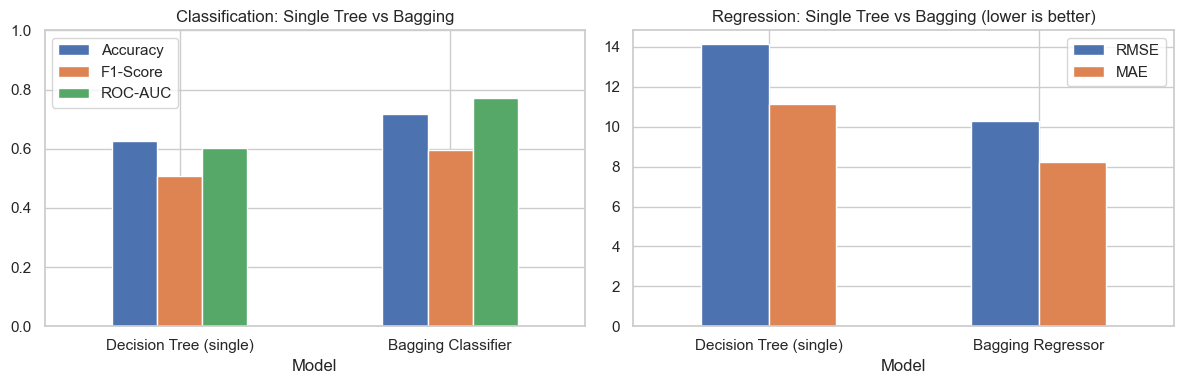

5-fold CV ROC-AUC  Single Tree: 0.6143 ± 0.0097   |   Bagging: 0.7593 ± 0.0103


In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
c = pd.DataFrame(clf_results).set_index("Model")[["Accuracy", "F1-Score", "ROC-AUC"]]
c.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Classification: Single Tree vs Bagging"); ax[0].set_ylim(0, 1)
r = pd.DataFrame(reg_results).set_index("Model")[["RMSE", "MAE"]]
r.plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Regression: Single Tree vs Bagging (lower is better)")
save_fig("03_bagging_vs_single")

m1, s1 = cv_scores(DecisionTreeClassifier(random_state=RANDOM_STATE), "clf")
m2, s2 = cv_scores(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                     n_estimators=100, max_samples=0.8, n_jobs=1, random_state=RANDOM_STATE), "clf")
print(f"5-fold CV ROC-AUC  Single Tree: {m1:.4f} ± {s1:.4f}   |   Bagging: {m2:.4f} ± {s2:.4f}")

**Interpretation:** A single fully-grown tree has *high variance* (memorises training data). Bagging averages 100 trees trained on different bootstrap samples, which reduces variance, so ROC-AUC / R² go up and RMSE goes down compared to the single tree.

# Part D: Boosting Algorithms
## AdaBoost

### Task 12 AdaBoost Classifier

In [47]:
evaluate_clf("AdaBoost Classifier",
             AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE), "Boosting")
evaluate_clf("Decision Stump (weak learner)", DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE), "Base")
pd.DataFrame(clf_results).round(4)

,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (single),Base,0.6250,0.5000,0.5179,0.5088,0.6036
1,Bagging Classifier,Bagging,0.7163,0.6401,0.5564,0.5953,0.7727
2,AdaBoost Classifier,Boosting,0.7298,0.6730,0.5436,0.6014,0.7870
3,Decision Stump (weak learner),Base,0.6625,0.5572,0.4872,0.5198,0.6274


### Task 13 AdaBoost Regressor

In [48]:
evaluate_reg("AdaBoost Regressor",
             AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3),
                               n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE), "Boosting")
evaluate_reg("Shallow Tree depth=3 (weak learner)", DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE), "Base")
pd.DataFrame(reg_results).round(4)

,Model,Family,MAE,RMSE,R2
0,Decision Tree (single),Base,11.1198,14.1222,-0.0955
1,Bagging Regressor,Bagging,8.2389,10.2893,0.4184
2,AdaBoost Regressor,Boosting,8.6941,10.6530,0.3766
3,Shallow Tree depth=3 (weak learner),Base,9.3800,11.5976,0.2611


### Task 14 Analyze how weak learners improve sequentially

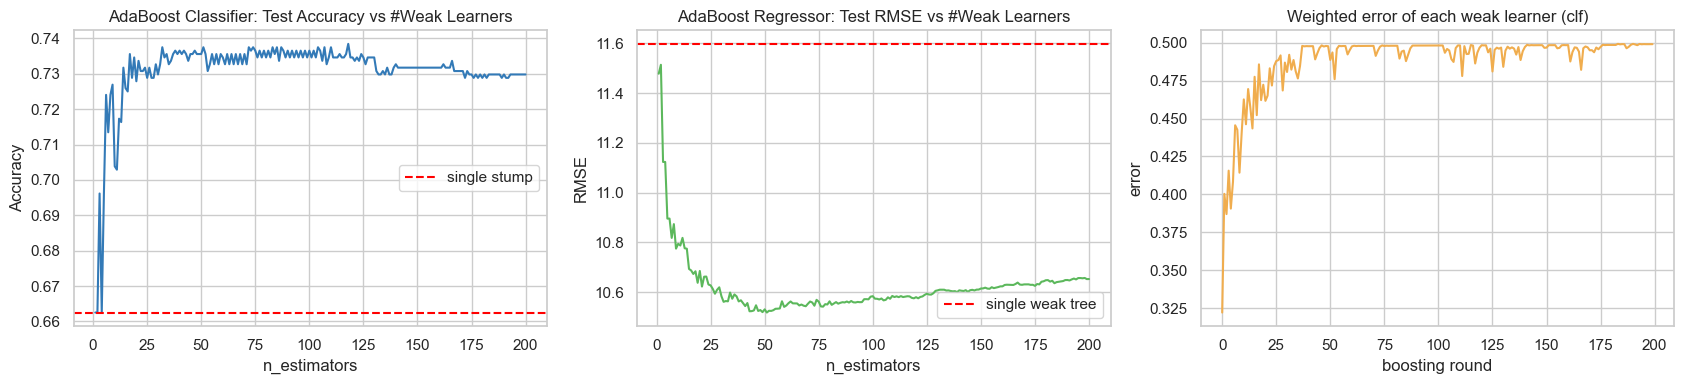

Accuracy after 1 / 10 / 50 / 200 learners: 0.662 / 0.704 / 0.736 / 0.730
RMSE     after 1 / 10 / 50 / 200 learners: 11.48 / 10.79 / 10.53 / 10.65


In [49]:
ada_c = clf_models["AdaBoost Classifier"]; ada_r = reg_models["AdaBoost Regressor"]
Xte_c = ada_c.named_steps["prep"].transform(X_test)
Xte_r = ada_r.named_steps["prep"].transform(X_test)

acc_stage = [accuracy_score(yc_test, p) for p in ada_c.named_steps["model"].staged_predict(Xte_c)]
rmse_stage = [root_mean_squared_error(yr_test, p) for p in ada_r.named_steps["model"].staged_predict(Xte_r)]
stump_acc = clf_results[[r["Model"] for r in clf_results].index("Decision Stump (weak learner)")]["Accuracy"]
weak_rmse = reg_results[[r["Model"] for r in reg_results].index("Shallow Tree depth=3 (weak learner)")]["RMSE"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(range(1, len(acc_stage) + 1), acc_stage, color="#337ab7")
ax[0].axhline(stump_acc, color="red", ls="--", label="single stump"); ax[0].legend()
ax[0].set_title("AdaBoost Classifier: Test Accuracy vs #Weak Learners"); ax[0].set_xlabel("n_estimators"); ax[0].set_ylabel("Accuracy")
ax[1].plot(range(1, len(rmse_stage) + 1), rmse_stage, color="#5cb85c")
ax[1].axhline(weak_rmse, color="red", ls="--", label="single weak tree"); ax[1].legend()
ax[1].set_title("AdaBoost Regressor: Test RMSE vs #Weak Learners"); ax[1].set_xlabel("n_estimators"); ax[1].set_ylabel("RMSE")
errs = ada_c.named_steps["model"].estimator_errors_
ax[2].plot(errs, color="#f0ad4e"); ax[2].set_title("Weighted error of each weak learner (clf)")
ax[2].set_xlabel("boosting round"); ax[2].set_ylabel("error")
save_fig("04_adaboost_sequential")
print(f"Accuracy after 1 / 10 / 50 / 200 learners: {acc_stage[0]:.3f} / {acc_stage[9]:.3f} / {acc_stage[49]:.3f} / {acc_stage[-1]:.3f}")
print(f"RMSE     after 1 / 10 / 50 / 200 learners: {rmse_stage[0]:.2f} / {rmse_stage[9]:.2f} / {rmse_stage[49]:.2f} / {rmse_stage[-1]:.2f}")

**Interpretation:** Every round AdaBoost increases the weight of samples that earlier learners got wrong, so the next weak learner focuses on the *hard* students.
The curve shows performance improving quickly in the first rounds and then flattening — individual weak learners are poor, but the **weighted combination** beats the single weak model.
The rising weighted error per round shows that later learners are dealing with harder (re-weighted) samples.

## XGBoost

### Task 15 XGBoost Classifier

In [50]:
evaluate_clf("XGBoost Classifier",
             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                           colsample_bytree=0.8, reg_lambda=1.0, eval_metric="logloss",
                           random_state=RANDOM_STATE, n_jobs=-1), "Boosting")
evaluate_clf("Gradient Boosting Classifier",
             GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE), "Boosting")
pd.DataFrame(clf_results).round(4)

,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (single),Base,0.6250,0.5000,0.5179,0.5088,0.6036
1,Bagging Classifier,Bagging,0.7163,0.6401,0.5564,0.5953,0.7727
2,AdaBoost Classifier,Boosting,0.7298,0.6730,0.5436,0.6014,0.7870
3,Decision Stump (weak learner),Base,0.6625,0.5572,0.4872,0.5198,0.6274
4,XGBoost Classifier,Boosting,0.7317,0.6628,0.5795,0.6183,0.7812
5,Gradient Boosting Classifier,Boosting,0.7356,0.6706,0.5795,0.6217,0.7904


### Task 16 XGBoost Regressor

In [51]:
evaluate_reg("XGBoost Regressor",
             XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                          colsample_bytree=0.8, reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1), "Boosting")
evaluate_reg("Gradient Boosting Regressor",
             GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE), "Boosting")
pd.DataFrame(reg_results).round(4)

,Model,Family,MAE,RMSE,R2
0,Decision Tree (single),Base,11.1198,14.1222,-0.0955
1,Bagging Regressor,Bagging,8.2389,10.2893,0.4184
2,AdaBoost Regressor,Boosting,8.6941,10.6530,0.3766
3,Shallow Tree depth=3 (weak learner),Base,9.3800,11.5976,0.2611
4,XGBoost Regressor,Boosting,8.2417,10.2149,0.4268
5,Gradient Boosting Regressor,Boosting,8.1631,10.1468,0.4344


### Task 17 Compare performance and robustness with other boosting models

,Boosting model,Task,CV metric,Mean,Std (robustness)
0,AdaBoost,Classification,ROC-AUC,0.7724,0.0093
1,Gradient Boosting,Classification,ROC-AUC,0.7721,0.0082
2,XGBoost,Classification,ROC-AUC,0.7653,0.0063
3,AdaBoost,Regression,R2,0.4121,0.0212
4,Gradient Boosting,Regression,R2,0.4829,0.0274
5,XGBoost,Regression,R2,0.4787,0.0287


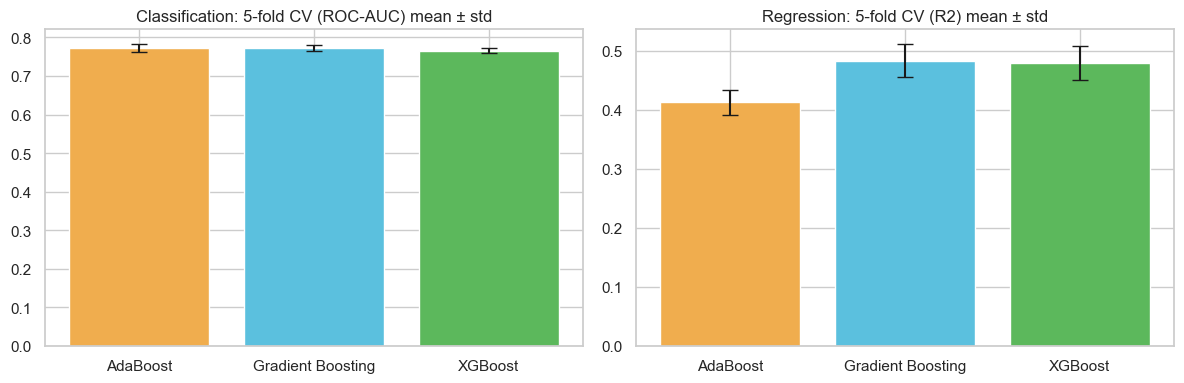

In [52]:
boost_clf = {"AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
             "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
             "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)}
boost_reg = {"AdaBoost": AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
             "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
             "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1)}

rows = []
for n in boost_clf:
    m, s = cv_scores(boost_clf[n], "clf"); rows.append({"Boosting model": n, "Task": "Classification", "CV metric": "ROC-AUC", "Mean": m, "Std (robustness)": s})
for n in boost_reg:
    m, s = cv_scores(boost_reg[n], "reg"); rows.append({"Boosting model": n, "Task": "Regression", "CV metric": "R2", "Mean": m, "Std (robustness)": s})
robust = pd.DataFrame(rows)
display(robust.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, t in zip(ax, ["Classification", "Regression"]):
    d = robust[robust.Task == t]
    a.bar(d["Boosting model"], d["Mean"], yerr=d["Std (robustness)"], capsize=6, color=["#f0ad4e", "#5bc0de", "#5cb85c"])
    a.set_title(f"{t}: 5-fold CV ({d['CV metric'].iloc[0]}) mean ± std")
save_fig("05_boosting_robustness")

**Interpretation:** Mean = performance, Std = robustness (lower std → stable across folds). Compare the three boosting algorithms in the table: XGBoost/Gradient Boosting use deeper trees + regularisation and are usually stronger than AdaBoost with stumps.

# Part E: Voting & Stacking Ensembles

### Task 18 & 19 Voting Classifier: Hard vs Soft

In [53]:
def base_estimators():
    return [("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
            ("knn", KNeighborsClassifier(n_neighbors=15)),
            ("dt", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
            ("rf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))]

for n, m in base_estimators():
    evaluate_clf({"lr": "Logistic Regression", "knn": "KNN", "dt": "Decision Tree (depth 5)", "rf": "Random Forest"}[n], m, "Base")

evaluate_clf("Voting Classifier (Hard)", VotingClassifier(base_estimators(), voting="hard"), "Voting")
evaluate_clf("Voting Classifier (Soft)", VotingClassifier(base_estimators(), voting="soft"), "Voting")
vt = pd.DataFrame(clf_results)
vt[vt.Family.isin(["Base", "Voting"])].round(4)

,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (single),Base,0.6250,0.5000,0.5179,0.5088,0.6036
3,Decision Stump (weak learner),Base,0.6625,0.5572,0.4872,0.5198,0.6274
6,Logistic Regression,Base,0.7423,0.6826,0.5846,0.6298,0.7928
7,KNN,Base,0.6990,0.6442,0.4410,0.5236,0.7310
8,Decision Tree (depth 5),Base,0.7029,0.6588,0.4308,0.5209,0.7547
9,Random Forest,Base,0.7260,0.6721,0.5256,0.5899,0.7748
10,Voting Classifier (Hard),Voting,0.7279,0.7034,0.4744,0.5666,0.6772
11,Voting Classifier (Soft),Voting,0.7288,0.6812,0.5205,0.5901,0.7831


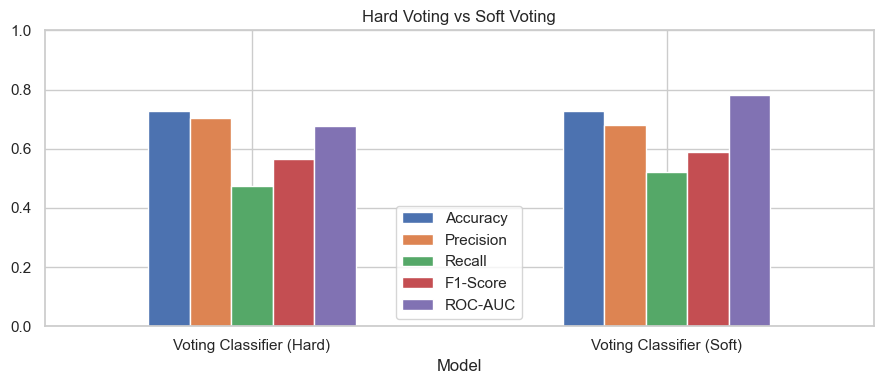

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Voting Classifier (Hard),0.7279,0.7034,0.4744,0.5666,0.6772
Voting Classifier (Soft),0.7288,0.6812,0.5205,0.5901,0.7831


In [54]:
hs = vt[vt.Model.str.contains("Voting")].set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]]
hs.plot(kind="bar", figsize=(9, 4), rot=0); plt.ylim(0, 1); plt.title("Hard Voting vs Soft Voting")
save_fig("06_hard_vs_soft_voting")
hs.round(4)

**Interpretation:** *Hard* voting only counts class labels, so every model has equal say and the ROC-AUC is computed from labels only. *Soft* voting averages probabilities, so confident models count more and it gives a proper probability → usually better ROC-AUC.

### Task 20 Stacking Classifier with a meta-learner

In [55]:
stack_clf = StackingClassifier(
    estimators=[("rf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
                ("xgb", XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
                ("knn", KNeighborsClassifier(n_neighbors=15)),
                ("ada", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=100, random_state=RANDOM_STATE))],
    final_estimator=LogisticRegression(max_iter=1000),     # meta-learner
    cv=5, stack_method="predict_proba", n_jobs=-1)
evaluate_clf("Stacking Classifier", stack_clf, "Stacking")
pd.DataFrame(clf_results).tail(1).round(4)

,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
12,Stacking Classifier,Stacking,0.7346,0.6804,0.5513,0.6091,0.7871


### Task 21 Stacking Regressor for score prediction

In [56]:
stack_reg = StackingRegressor(
    estimators=[("rf", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
                ("xgb", XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE, n_jobs=1)),
                ("knn", KNeighborsRegressor(n_neighbors=15)),
                ("ada", AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3), n_estimators=100, random_state=RANDOM_STATE))],
    final_estimator=Ridge(alpha=1.0),                       # meta-learner
    cv=5, n_jobs=-1)
evaluate_reg("Stacking Regressor", stack_reg, "Stacking")
pd.DataFrame(reg_results).tail(1).round(4)

,Model,Family,MAE,RMSE,R2
6,Stacking Regressor,Stacking,8.196,10.185,0.4302


**Interpretation:** Base models give out-of-fold predictions; the meta-learner (Logistic / Ridge) learns how much to trust each base model. This is the most flexible ensemble but also the slowest to train.

# Part F: Model Evaluation & Comparison

### Task 22 Evaluate classification models (Accuracy, Precision, Recall, F1, ROC-AUC)

,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,Base,0.7423,0.6826,0.5846,0.6298,0.7928
1,Gradient Boosting Classifier,Boosting,0.7356,0.6706,0.5795,0.6217,0.7904
2,Stacking Classifier,Stacking,0.7346,0.6804,0.5513,0.6091,0.7871
3,AdaBoost Classifier,Boosting,0.7298,0.6730,0.5436,0.6014,0.7870
4,Voting Classifier (Soft),Voting,0.7288,0.6812,0.5205,0.5901,0.7831
5,XGBoost Classifier,Boosting,0.7317,0.6628,0.5795,0.6183,0.7812
6,Random Forest,Base,0.7260,0.6721,0.5256,0.5899,0.7748
7,Bagging Classifier,Bagging,0.7163,0.6401,0.5564,0.5953,0.7727
8,Decision Tree (depth 5),Base,0.7029,0.6588,0.4308,0.5209,0.7547
9,KNN,Base,0.6990,0.6442,0.4410,0.5236,0.7310


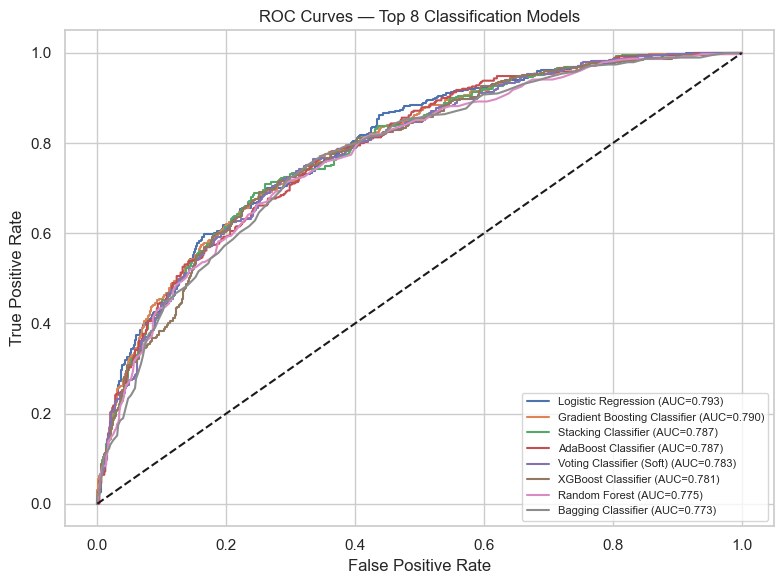

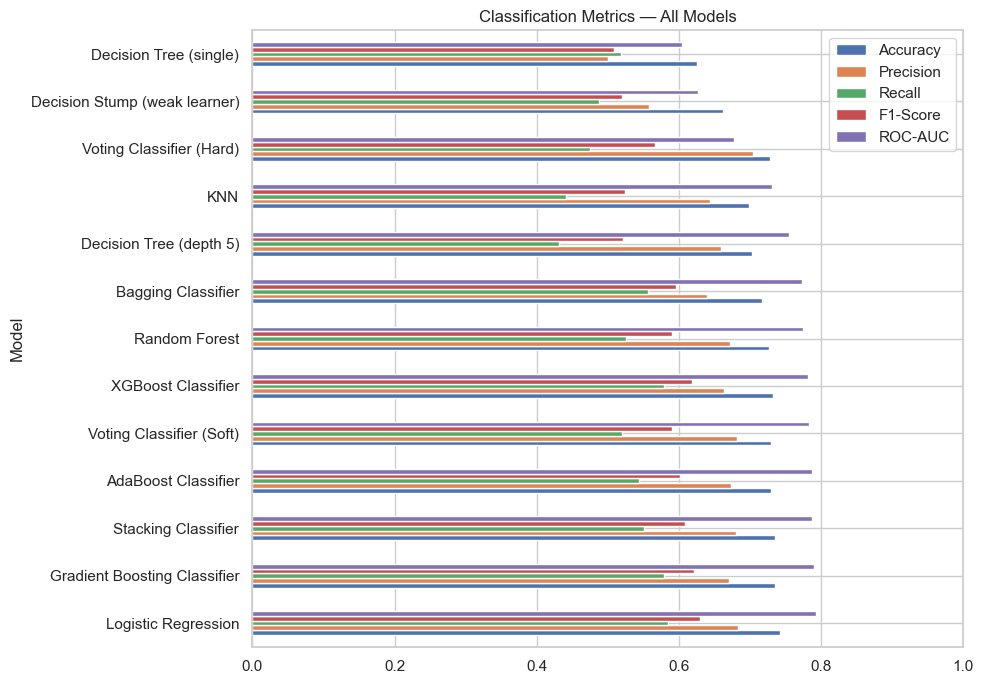

In [57]:
clf_df = pd.DataFrame(clf_results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(clf_df.round(4))
clf_df.to_csv("models/classification_results.csv", index=False)

plt.figure(figsize=(8, 6))
for name in clf_df.Model.head(8):
    p = clf_models[name]
    s = p.predict_proba(X_test)[:, 1] if hasattr(p, "predict_proba") else p.predict(X_test)
    fpr, tpr, _ = roc_curve(yc_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Top 8 Classification Models"); plt.legend(fontsize=8)
save_fig("07_roc_curves")

clf_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(kind="barh", figsize=(10, 7))
plt.title("Classification Metrics — All Models"); plt.xlim(0, 1)
save_fig("08_classification_comparison")

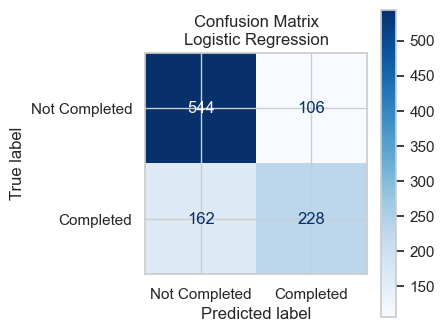

In [58]:
best_clf_name = clf_df.sort_values(["ROC-AUC", "F1-Score"], ascending=False).iloc[0]["Model"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(clf_models[best_clf_name], X_test, yc_test, display_labels=["Not Completed", "Completed"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion Matrix\n{best_clf_name}")
save_fig("09_confusion_matrix_best")

**Interpretation:** ROC-AUC (threshold-independent) is used as the main ranking metric, F1 as tie-breaker, since classes are imbalanced. The confusion matrix shows where the best model still makes mistakes.

### Task 23 Evaluate regression models (MAE, RMSE, R²)

,Model,Family,MAE,RMSE,R2
0,Gradient Boosting Regressor,Boosting,8.1631,10.1468,0.4344
1,Stacking Regressor,Stacking,8.1960,10.1850,0.4302
2,XGBoost Regressor,Boosting,8.2417,10.2149,0.4268
3,Bagging Regressor,Bagging,8.2389,10.2893,0.4184
4,AdaBoost Regressor,Boosting,8.6941,10.6530,0.3766
5,Shallow Tree depth=3 (weak learner),Base,9.3800,11.5976,0.2611
6,Decision Tree (single),Base,11.1198,14.1222,-0.0955


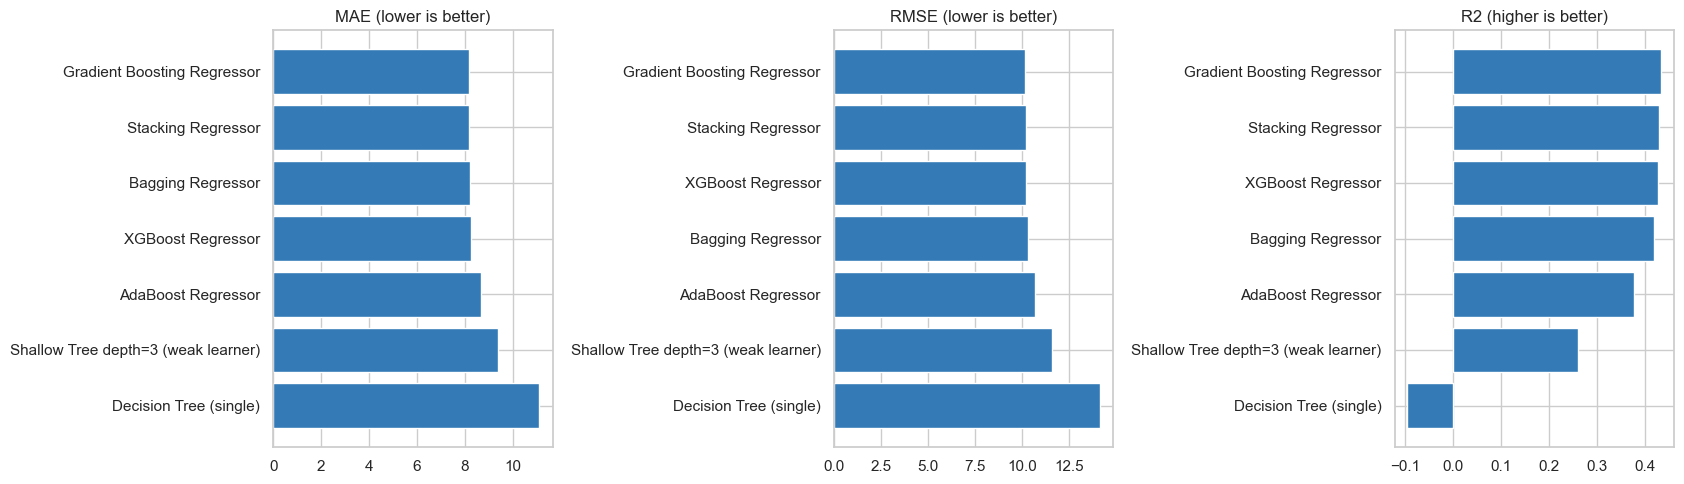

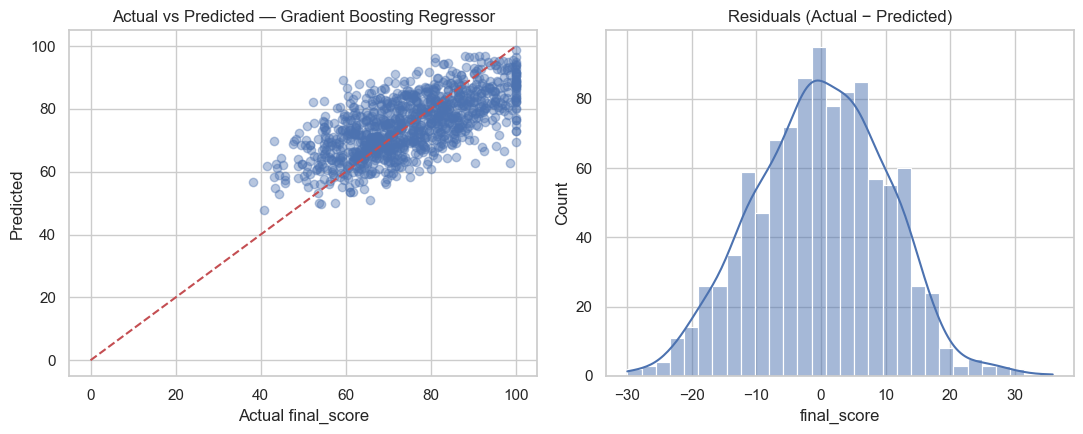

In [59]:
reg_df = pd.DataFrame(reg_results).sort_values("RMSE").reset_index(drop=True)
display(reg_df.round(4))
reg_df.to_csv("models/regression_results.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, m in zip(ax, ["MAE", "RMSE", "R2"]):
    d = reg_df.sort_values(m, ascending=(m != "R2"))
    a.barh(d.Model, d[m], color="#337ab7"); a.invert_yaxis(); a.set_title(m + (" (higher is better)" if m == "R2" else " (lower is better)"))
save_fig("10_regression_comparison")

best_reg_name = reg_df.sort_values(["RMSE", "MAE"]).iloc[0]["Model"]
pred = reg_models[best_reg_name].predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(yr_test, pred, alpha=0.4); ax[0].plot([0, 100], [0, 100], "r--")
ax[0].set_xlabel("Actual final_score"); ax[0].set_ylabel("Predicted"); ax[0].set_title(f"Actual vs Predicted — {best_reg_name}")
sns.histplot(yr_test - pred, bins=30, kde=True, ax=ax[1]); ax[1].set_title("Residuals (Actual − Predicted)")
save_fig("11_regression_best_actual_vs_pred")

**Interpretation:** RMSE penalises large errors more than MAE; R² tells how much variance of `final_score` the model explains. Points close to the red diagonal and residuals centred on 0 = good model.

### Task 24 Compare all ensemble techniques & identify the best model for each task

In [ ]:
ens_clf = clf_df[~clf_df.Family.eq("Base")].copy()
ens_reg = reg_df[~reg_df.Family.eq("Base")].copy()

print("ENSEMBLE MODELS — CLASSIFICATION (sorted by ROC-AUC)"); display(ens_clf.round(4))
print("ENSEMBLE MODELS — REGRESSION (sorted by RMSE)");        display(ens_reg.round(4))

best_clf_name = ens_clf.sort_values(["ROC-AUC", "F1-Score"], ascending=False).iloc[0]["Model"]
best_reg_name = ens_reg.sort_values(["RMSE", "MAE"]).iloc[0]["Model"]
print(f"\n Best classification model : {best_clf_name}")
print(f" Best regression model     : {best_reg_name}")

fam_c = ens_clf.groupby("Family")[["Accuracy", "F1-Score", "ROC-AUC"]].max().round(4)
fam_r = ens_reg.groupby("Family").agg(RMSE=("RMSE", "min"), MAE=("MAE", "min"), R2=("R2", "max")).round(4)
display(fam_c); display(fam_r)

ENSEMBLE MODELS — CLASSIFICATION (sorted by ROC-AUC)


,Model,Family,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Gradient Boosting Classifier,Boosting,0.7356,0.6706,0.5795,0.6217,0.7904
2,Stacking Classifier,Stacking,0.7346,0.6804,0.5513,0.6091,0.7871
3,AdaBoost Classifier,Boosting,0.7298,0.6730,0.5436,0.6014,0.7870
4,Voting Classifier (Soft),Voting,0.7288,0.6812,0.5205,0.5901,0.7831
5,XGBoost Classifier,Boosting,0.7317,0.6628,0.5795,0.6183,0.7812
7,Bagging Classifier,Bagging,0.7163,0.6401,0.5564,0.5953,0.7727
10,Voting Classifier (Hard),Voting,0.7279,0.7034,0.4744,0.5666,0.6772


ENSEMBLE MODELS — REGRESSION (sorted by RMSE)


,Model,Family,MAE,RMSE,R2
0,Gradient Boosting Regressor,Boosting,8.1631,10.1468,0.4344
1,Stacking Regressor,Stacking,8.1960,10.1850,0.4302
2,XGBoost Regressor,Boosting,8.2417,10.2149,0.4268
3,Bagging Regressor,Bagging,8.2389,10.2893,0.4184
4,AdaBoost Regressor,Boosting,8.6941,10.6530,0.3766



 Best classification model : Gradient Boosting Classifier
 Best regression model     : Gradient Boosting Regressor


,Accuracy,F1-Score,ROC-AUC
Family,,,
Bagging,0.7163,0.5953,0.7727
Boosting,0.7356,0.6217,0.7904
Stacking,0.7346,0.6091,0.7871
Voting,0.7288,0.5901,0.7831


,RMSE,MAE,R2
Family,,,
Bagging,10.2893,8.2389,0.4184
Boosting,10.1468,8.1631,0.4344
Stacking,10.1850,8.1960,0.4302


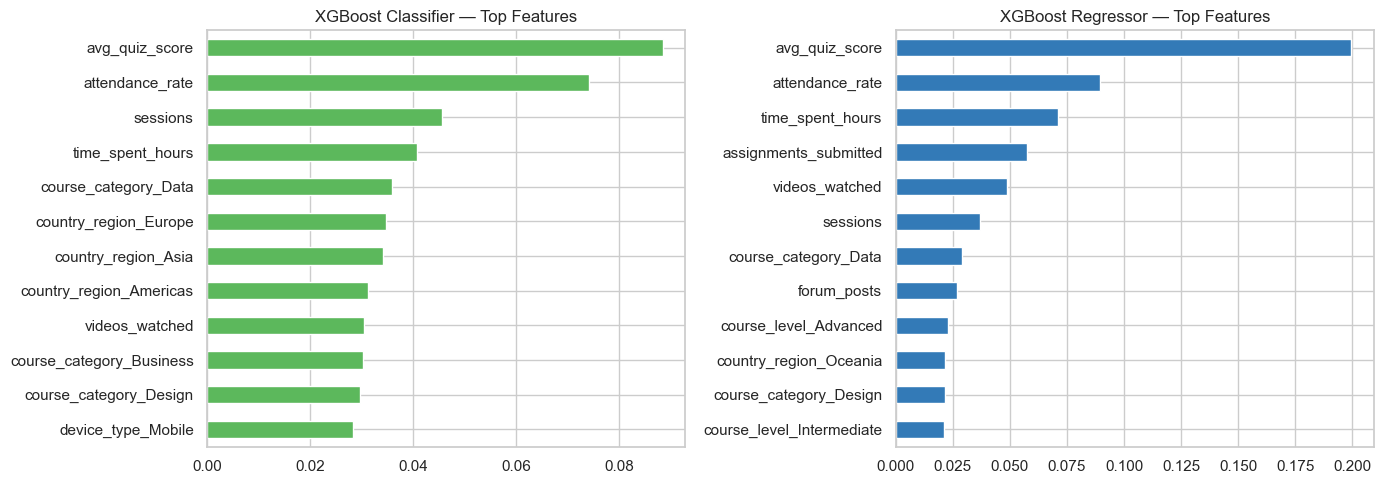

In [61]:
def get_importance(pipe, top=12):
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pipe.named_steps["model"].feature_importances_
    return pd.Series(imp, index=[n.split("__")[1] for n in names]).sort_values(ascending=False).head(top)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
get_importance(clf_models["XGBoost Classifier"])[::-1].plot(kind="barh", ax=ax[0], color="#5cb85c"); ax[0].set_title("XGBoost Classifier — Top Features")
get_importance(reg_models["XGBoost Regressor"])[::-1].plot(kind="barh", ax=ax[1], color="#337ab7"); ax[1].set_title("XGBoost Regressor — Top Features")
save_fig("12_feature_importance")

In [62]:
joblib.dump(clf_models[best_clf_name], "models/best_classifier.joblib")
joblib.dump(reg_models[best_reg_name], "models/best_regressor.joblib")

meta = {"num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
        "best_classifier": best_clf_name, "best_regressor": best_reg_name,
        "num_ranges": {c: [float(df[c].min()), float(df[c].max()), float(df[c].median())] for c in NUM_FEATURES},
        "cat_options": {c: sorted(df[c].dropna().unique().tolist()) for c in CAT_FEATURES}}
json.dump(meta, open("models/metadata.json", "w"), indent=2)
print("Saved: models/best_classifier.joblib, models/best_regressor.joblib, models/metadata.json")

Saved: models/best_classifier.joblib, models/best_regressor.joblib, models/metadata.json


# Part G: Final Analysis & Reporting

### Task 25 Final report

In [63]:
from IPython.display import Markdown
g = lambda df_, m, col: df_[df_.Model == m].iloc[0][col]

bag_c, ada_c_, xgb_c = g(clf_df, "Bagging Classifier", "ROC-AUC"), g(clf_df, "AdaBoost Classifier", "ROC-AUC"), g(clf_df, "XGBoost Classifier", "ROC-AUC")
bag_r, ada_r_, xgb_r = g(reg_df, "Bagging Regressor", "RMSE"), g(reg_df, "AdaBoost Regressor", "RMSE"), g(reg_df, "XGBoost Regressor", "RMSE")
single_c, single_r = g(clf_df, "Decision Tree (single)", "ROC-AUC"), g(reg_df, "Decision Tree (single)", "RMSE")
vs_h, vs_s = g(clf_df, "Voting Classifier (Hard)", "ROC-AUC"), g(clf_df, "Voting Classifier (Soft)", "ROC-AUC")
st_c, st_r = g(clf_df, "Stacking Classifier", "ROC-AUC"), g(reg_df, "Stacking Regressor", "RMSE")
lr_c = g(clf_df, 'Logistic Regression', 'ROC-AUC')
bc = clf_df[clf_df.Model == best_clf_name].iloc[0]; br = reg_df[reg_df.Model == best_reg_name].iloc[0]

Markdown(f'''
## 1. Impact of Bagging vs Boosting
| | Single Tree | Bagging | AdaBoost | XGBoost |
|---|---|---|---|---|
| Classification ROC-AUC | {single_c:.3f} | {bag_c:.3f} | {ada_c_:.3f} | {xgb_c:.3f} |
| Regression RMSE | {single_r:.2f} | {bag_r:.2f} | {ada_r_:.2f} | {xgb_r:.2f} |

Bagging reduces the **variance** of a single overfit tree; boosting reduces **bias** by correcting errors step-by-step.

## 2. Comparison of tree-based boosting algorithms
AdaBoost (stumps, re-weighting) vs Gradient Boosting vs XGBoost (regularised gradient boosting) — see the robustness table in Task 17 (CV mean ± std).

## 3. Advantages of Voting and Stacking
- **Voting** (Hard ROC-AUC {vs_h:.3f}, Soft {vs_s:.3f}): simple, diverse models, soft voting uses probabilities.
- **Stacking** (ROC-AUC {st_c:.3f}, RMSE {st_r:.2f}): meta-learner learns the best combination of base models; most flexible but costlier to train.

**Honest observation:** the plain Logistic Regression baseline (ROC-AUC {lr_c:.3f}) is very close to the best ensemble, which means the completion pattern is largely linear. Ensembles clearly beat the *single tree* (huge gain in stability), and for regression every ensemble beats the single/weak tree by a large margin.

## 4. Final model recommendation for deployment
- **Classification (course completion): `{best_clf_name}`** → Accuracy {bc["Accuracy"]:.3f}, F1 {bc["F1-Score"]:.3f}, ROC-AUC {bc["ROC-AUC"]:.3f}
- **Regression (final score): `{best_reg_name}`** → MAE {br["MAE"]:.2f}, RMSE {br["RMSE"]:.2f}, R² {br["R2"]:.3f}
''')


## 1. Impact of Bagging vs Boosting
| | Single Tree | Bagging | AdaBoost | XGBoost |
|---|---|---|---|---|
| Classification ROC-AUC | 0.604 | 0.773 | 0.787 | 0.781 |
| Regression RMSE | 14.12 | 10.29 | 10.65 | 10.21 |

Bagging reduces the **variance** of a single overfit tree; boosting reduces **bias** by correcting errors step-by-step.

## 2. Comparison of tree-based boosting algorithms
AdaBoost (stumps, re-weighting) vs Gradient Boosting vs XGBoost (regularised gradient boosting) — see the robustness table in Task 17 (CV mean ± std).

## 3. Advantages of Voting and Stacking
- **Voting** (Hard ROC-AUC 0.677, Soft 0.783): simple, diverse models, soft voting uses probabilities.
- **Stacking** (ROC-AUC 0.787, RMSE 10.18): meta-learner learns the best combination of base models; most flexible but costlier to train.

**Honest observation:** the plain Logistic Regression baseline (ROC-AUC 0.793) is very close to the best ensemble, which means the completion pattern is largely linear. Ensembles clearly beat the *single tree* (huge gain in stability), and for regression every ensemble beats the single/weak tree by a large margin.

## 4. Final model recommendation for deployment
- **Classification (course completion): `Gradient Boosting Classifier`** → Accuracy 0.736, F1 0.622, ROC-AUC 0.790
- **Regression (final score): `Gradient Boosting Regressor`** → MAE 8.16, RMSE 10.15, R² 0.434


### Business Interpretation
- Students predicted as **"Not Completed"** can be targeted early with reminders, mentoring or easier content to reduce drop-outs.
- Predicted **final score** helps the platform identify students who may need extra support *before* the course ends.
- Ensemble models are more **stable** than a single model, which is exactly the problem the manager reported ("single models are producing unstable results").
- The trained pipelines (preprocessing + model) are saved and served via a **Streamlit app** for real-time use.